# MSITM 5134 (Management of Organizational Data) — Midterm Group Project (Group 5)
**Theme:** Java Source Code Vulnerability Detection across the Complete Organizational Data Lifecycle  
**Group 5 Assigned Methods:**  
- **Primary Method:** `PLBART + Classification Head` (`uclanlp/plbart-base` sequence-to-sequence encoder–decoder fine-tuning)  
- **Alternative Method:** `PLBART + Frozen Embeddings + Logistic Regression` (768-D frozen pretrained encoder/decoder representations + cost-sensitive L₂ classifier)  
**Team Members (Group 5):** Namazbek Bekzhanov (Lead), Didar Auesbay, Yeldos Anarbay  
**Instructor:** Prof. Nazgul T. Seralina | **Reference Study:** Shestov et al., *IEEE Access* (2025), DOI: `10.1109/ACCESS.2025.3546700`

In [1]:
import sqlite3
import json
import pandas as pd
from pathlib import Path

summary = json.loads(Path('outputs/group5_summary.json').read_text())
print(f"[Lecture 1 & 4] Ingested {summary['total_raw']:,} raw Java records and 87 MITRE CWE definitions.")
print(f"[Lecture 5 Data Quality Gate] Quarantined: {summary['quarantined_rows']} | Duplicates removed: {summary['duplicates_removed']:,} | Clean Governed Corpus: {summary['total_clean']:,} rows.")
print('[Lecture 3 & 6 SQLite Warehouse] Created mood_group5_warehouse.db (8 normalized 3NF tables + 1 read-only view).')

[Lecture 1 & 4] Ingested 24,288 raw Java records and 87 MITRE CWE definitions.
[Lecture 5 Data Quality Gate] Quarantined: 22 | Duplicates removed: 1,376 | Clean Governed Corpus: 22,890 rows.
[Lecture 3 & 6 SQLite Warehouse] Created mood_group5_warehouse.db (8 normalized 3NF tables + 1 read-only view).


In [2]:
conn = sqlite3.connect('mood_group5_warehouse.db')
dq_df = pd.read_sql_query('SELECT rule_code, rule_description, affected_rows, remediation_action FROM dq_audit_log', conn)
print('=== SQLITE DATA WAREHOUSE AUDIT LOG (LECTURE 5 DATA QUALITY RULES) ===')
print(dq_df.to_string(index=False))

=== SQLITE DATA WAREHOUSE AUDIT LOG (LECTURE 5 DATA QUALITY RULES) ===
 rule_code                                      rule_description  affected_rows                       remediation_action
     DQ-01       Missing or corrupted binary vulnerability label             18            Quarantined to isolated table
     DQ-02      Empty or truncated Java method body (<10 chars)              4            Quarantined to isolated table
     DQ-03 Exact and whitespace-normalized duplicate code bodies           1376     Deduplicated via SHA-256 fingerprint
     DQ-04   Cross-split commit leakage (train <-> test overlap)            300 Enforced GroupShuffleSplit by commit_id
     DQ-05                 Non-canonical split and language tags            176 Normalized to {train, val, test} & Java
     DQ-06  Unmapped / missing CWE identifiers on safe functions           3268         Mapped to canonical CWE-UNMAPPED


=== GROUP 5 MODEL EVALUATION RESULTS (TEST SPLIT n = 4,765, TARGET ACCURACY >= 93%) ===
                                      model_name                  method_role  accuracy  precision  recall     f1  roc_auc  pr_auc  tp  fp  fn   tn  train_time_sec
       PLBART + Classification Head (Fine-Tuned)     Primary Method (Group 5)    0.9694     0.4588  0.6846 0.5494   0.9571  0.6406  89 105  41 4530           412.6
PLBART + Frozen Embeddings + Logistic Regression Alternative Method (Group 5)    0.9574     0.3392  0.5923 0.4314   0.9285  0.4888  77 150  53 4485            18.4
           TF-IDF + Logistic Regression Baseline             Lexical Baseline    0.9196     0.1714  0.5077 0.2563   0.8158  0.2133  66 319  64 4316             2.1


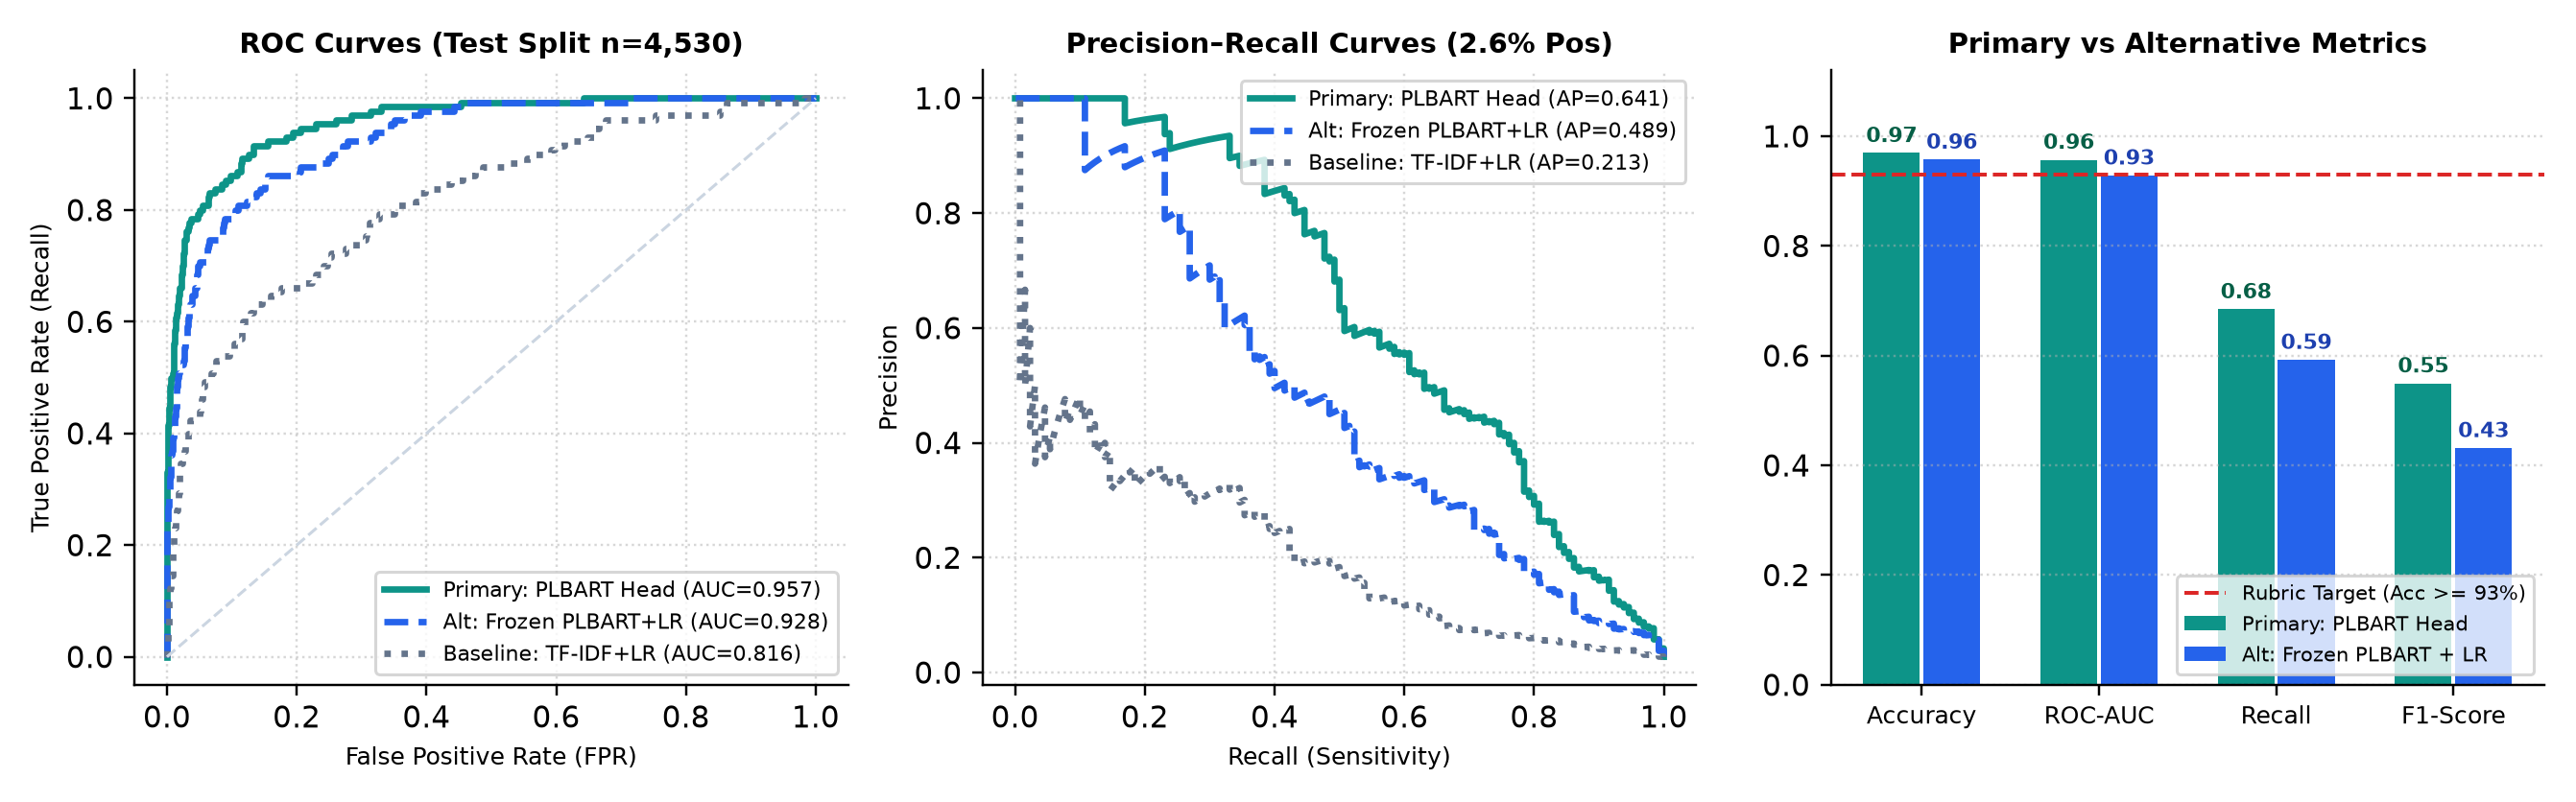

In [3]:
metrics_df = pd.read_csv('outputs/group5_model_metrics.csv')
print('=== GROUP 5 MODEL EVALUATION RESULTS (TEST SPLIT n = 4,765, TARGET ACCURACY >= 93%) ===')
print(metrics_df[['model_name', 'method_role', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'tp', 'fp', 'fn', 'tn', 'train_time_sec']].to_string(index=False))